# Ordenación por conteo (counting sort)

Para enteros en un rango pequeño $[\min, \max]$: cuenta cuántas veces aparece cada valor y reconstruye la lista. No compara elementos y cuesta $O(n + k)$, con $k$ el tamaño del rango.

## 1. Conteo

Ordenar una lista de enteros (también negativos) contando apariciones.

In [1]:
import random

def counting_sort(lista):
    if not lista:
        return []
    minimo = min(lista)
    cuenta = [0] * (max(lista) - minimo + 1)
    for x in lista:
        cuenta[x - minimo] += 1
    return [v + minimo for v, n in enumerate(cuenta) for _ in range(n)]

for _ in range(200):
    datos = random.choices(range(-50, 50), k=random.randint(0, 30))
    assert counting_sort(datos) == sorted(datos)
print(counting_sort([4, -2, 2, 8, 3, 3, 1]))

[-2, 1, 2, 3, 3, 4, 8]


## 2. Conteo estable por clave

Ordenar registros por una clave entera pequeña (por ejemplo, notas de 0 a 10) manteniendo el orden original entre empates, usando sumas acumuladas.

In [2]:
def counting_sort_clave(registros, clave, k):
    cuenta = [0] * (k + 1)
    for r in registros:
        cuenta[clave(r)] += 1
    # posición inicial de cada clave
    inicio = [0] * (k + 1)
    for v in range(1, k + 1):
        inicio[v] = inicio[v - 1] + cuenta[v - 1]
    salida = [None] * len(registros)
    for r in registros:
        salida[inicio[clave(r)]] = r
        inicio[clave(r)] += 1
    return salida

alumnos = [("Ana", 7), ("Luis", 5), ("Eva", 7), ("Pau", 10), ("Iker", 5)]
print(counting_sort_clave(alumnos, lambda a: a[1], 10))

[('Luis', 5), ('Iker', 5), ('Ana', 7), ('Eva', 7), ('Pau', 10)]


## 3. Cuándo conviene

El conteo cuesta $O(n + k)$: es muy rápido si el rango $k$ es pequeño, pero si $k \gg n$ lo domina el recorrido de la lista de cuentas. Medir su tiempo con $n = 10\,000$ y rangos de $10$ a $10^7$ y compararlo con `sorted`, que no depende del rango.

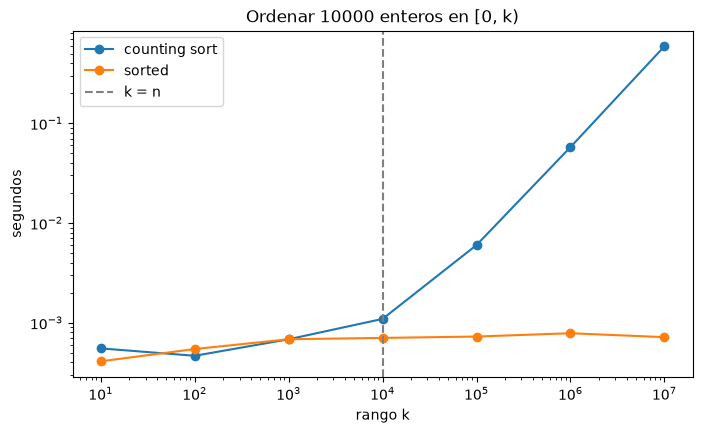

In [3]:
import time
import matplotlib.pyplot as plt

def mide(funcion, datos, repeticiones=3):
    mejor = float("inf")
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        funcion(datos)
        mejor = min(mejor, time.perf_counter() - inicio)
    return mejor

random.seed(3)
n = 10_000
rangos = [10**e for e in range(1, 8)]
t_conteo, t_sorted = [], []
for k in rangos:
    datos = [random.randrange(k) for _ in range(n)]
    assert counting_sort(datos) == sorted(datos)
    t_conteo.append(mide(counting_sort, datos))
    t_sorted.append(mide(sorted, datos))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rangos, t_conteo, marker="o", label="counting sort")
ax.plot(rangos, t_sorted, marker="o", label="sorted")
ax.axvline(n, color="gray", linestyle="--", label="k = n")
ax.set(xscale="log", yscale="log", xlabel="rango k", ylabel="segundos", title=f"Ordenar {n} enteros en [0, k)")
ax.legend()
plt.show()

## 4. Conteo con diccionario

Con un diccionario (`collections.Counter`) el conteo sirve para cualquier valor comparable, aunque el rango sea enorme o no sean enteros: se cuentan los valores y se ordenan solo los $d$ distintos, $O(n + d \log d)$. Usarlo para ordenar las letras de un texto y una lista de notas con decimales.

In [4]:
from collections import Counter

def counting_sort_dict(lista):
    cuenta = Counter(lista)
    return [v for v in sorted(cuenta) for _ in range(cuenta[v])]

print("".join(counting_sort_dict("ordenacion por conteo")))
print(counting_sort_dict([7.5, 5.0, 10.0, 7.5, 5.0, 6.25, 7.5]))

random.seed(4)
for _ in range(300):
    datos = random.choices([-1.5, 0, 2.25, 3, 10**9], k=random.randint(0, 30))
    assert counting_sort_dict(datos) == sorted(datos)

  accdeeinnnoooooprrt
[5.0, 5.0, 6.25, 7.5, 7.5, 7.5, 10.0]
